# Exercise 8 - DNN on CIFAR-10 dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

In [2]:
keras.utils.set_random_seed(42)

(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.cifar10.load_data()
X_train_full = X_train_full.astype("float32") / 255.
X_test = X_test.astype("float32") / 255.

y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

X_train, y_train = X_train_full[5000:], y_train_full[5000:]
X_val, y_val = X_train_full[:5000], y_train_full[:5000]

print(X_train.shape, X_val.shape, X_test.shape)

(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


In [3]:
def build_model(activation="swish", initializer="he_normal", batch_norm=False, dropout_rate=0.0):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(32, 32, 3)))
    model.add(keras.layers.Flatten())

    for _ in range(20):
        model.add(keras.layers.Dense(100, activation=None if batch_norm else activation, kernel_initializer=initializer))
        if batch_norm:
            model.add(keras.layers.BatchNormalization())
            model.add(keras.layers.Activation(activation))
        if dropout_rate:
            if activation == "selu":
                model.add(keras.layers.AlphaDropout(dropout_rate))
            else:
                model.add(keras.layers.Dropout(dropout_rate))

    model.add(keras.layers.Dense(10, activation="softmax"))
    return model

In [4]:
class ExponentialLearningRate(keras.callbacks.Callback):
    def __init__(self, min_lr=1e-5, max_lr=1.0, steps=400):
        super().__init__()
        self.min_lr = min_lr
        self.max_lr = max_lr
        self.steps = steps
        self.lrs = []
        self.losses = []

    def on_train_batch_begin(self, batch, logs=None):
        step = len(self.lrs)
        lr = self.min_lr * (self.max_lr / self.min_lr) ** (step / self.steps)
        self.model.optimizer.learning_rate.assign(lr)

    def on_train_batch_end(self, batch, logs=None):
        self.lrs.append(float(self.model.optimizer.learning_rate.numpy()))
        self.losses.append(logs["loss"])
        if len(self.lrs) >= self.steps:
            self.model.stop_training = True

def find_learning_rate(model, max_lr=1.0):
    lr_finder = ExponentialLearningRate(max_lr=max_lr)
    model.fit(X_train, y_train, epochs=1, batch_size=128, callbacks=[lr_finder], verbose=0)

    plt.figure(figsize=(8, 4))
    plt.plot(lr_finder.lrs, lr_finder.losses)
    plt.xscale("log")
    plt.xlabel("Learning rate")
    plt.ylabel("Training loss")
    plt.title("Learning rate finder")
    plt.grid(True)
    plt.show()

    return lr_finder

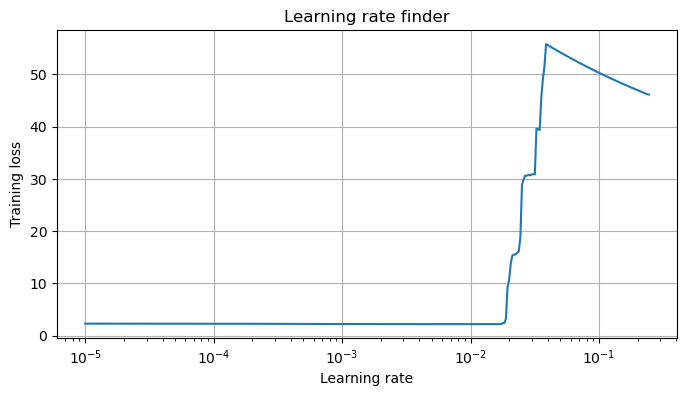

In [5]:
model = build_model()
model.compile(optimizer=keras.optimizers.Nadam(learning_rate=1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
lr_finder = find_learning_rate(model)

In [7]:
learning_rate = 0.01
def train_model(model, learning_rate, epochs=50, batch_size=128, callbacks=None):
    model.compile(optimizer=keras.optimizers.Nadam(learning_rate=learning_rate), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    early_stopping = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)
    all_callbacks = [early_stopping]
    if callbacks:
        all_callbacks.extend(callbacks)

    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size, callbacks=all_callbacks, verbose=1)
    return history

model = build_model()
history = train_model(model, learning_rate)

Epoch 1/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 48s 72ms/step - accuracy: 0.1642 - loss: 2.5935 - val_accuracy: 0.1956 - val_loss: 2.1475
Epoch 2/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 36s 59ms/step - accuracy: 0.2439 - loss: 1.9905 - val_accuracy: 0.2426 - val_loss: 2.1187
Epoch 3/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.1182 - loss: 114.4049 - val_accuracy: 0.0976 - val_loss: 2.3033
Epoch 4/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.0975 - loss: 2.3041 - val_accuracy: 0.0976 - val_loss: 2.3033
Epoch 5/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 30s 66ms/step - accuracy: 0.0968 - loss: 2.3042 - val_accuracy: 0.0976 - val_loss: 2.3034
Epoch 6/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 38s 58ms/step - accuracy: 0.0963 - loss: 2.3044 - val_accuracy: 0.0976 - val_loss: 2.3034
Epoch 7/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.0968 - loss: 2.3045 - val_accuracy: 0.0976 - val_loss: 2.3035


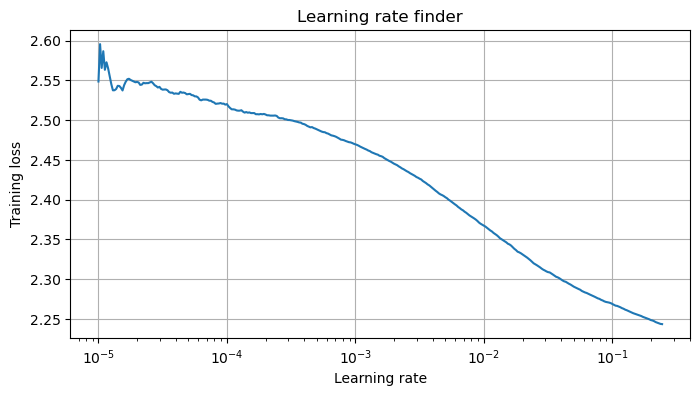

Epoch 1/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 80s 89ms/step - accuracy: 0.3718 - loss: 1.7207 - val_accuracy: 0.3518 - val_loss: 1.7554
Epoch 2/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 38s 81ms/step - accuracy: 0.4402 - loss: 1.5456 - val_accuracy: 0.3982 - val_loss: 1.6453
Epoch 3/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.4769 - loss: 1.4524 - val_accuracy: 0.4192 - val_loss: 1.6183
Epoch 4/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 43s 84ms/step - accuracy: 0.5072 - loss: 1.3799 - val_accuracy: 0.4142 - val_loss: 1.6281
Epoch 5/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 37s 74ms/step - accuracy: 0.5315 - loss: 1.3167 - val_accuracy: 0.3804 - val_loss: 1.7332
Epoch 6/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 29s 82ms/step - accuracy: 0.5541 - loss: 1.2587 - val_accuracy: 0.3698 - val_loss: 1.8280
Epoch 7/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 43s 86ms/step - accuracy: 0.5757 - loss: 1.2054 - val_accuracy: 0.3714 - val_loss: 1.8561
Epoch 8/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 40s 83ms/step - accuracy: 0.5928 - loss: 1.1591 - 

In [8]:
bn_model = build_model(batch_norm=True)
bn_model.compile(optimizer=keras.optimizers.Nadam(learning_rate=1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
bn_lr_finder = find_learning_rate(bn_model)
bn_learning_rate = 1e-3
bn_history = train_model(bn_model, bn_learning_rate)

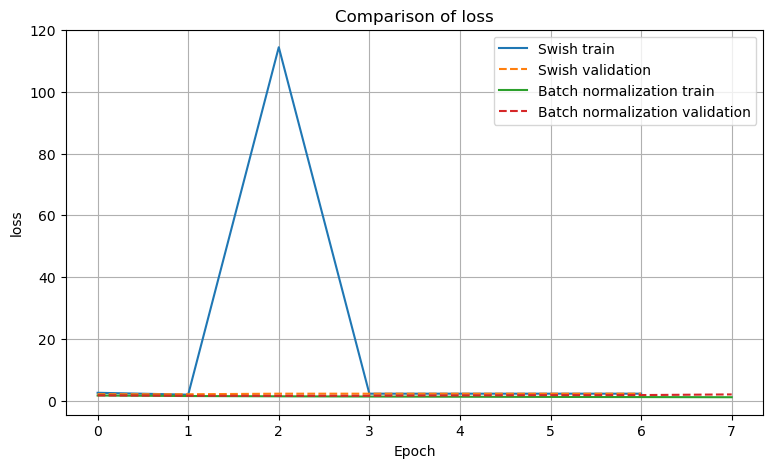

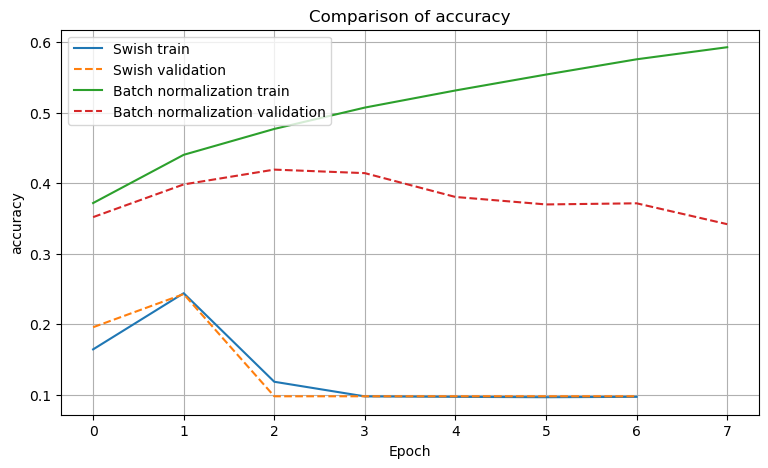

In [9]:
def compare_histories(histories, metric):
    plt.figure(figsize=(9, 5))

    for name, history in histories.items():
        plt.plot(history.history[metric], label=f"{name} train")
        plt.plot(history.history[f"val_{metric}"], "--", label=f"{name} validation")

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"Comparison of {metric}")
    plt.legend()
    plt.grid(True)
    plt.show()

compare_histories({"Swish": history, "Batch normalization": bn_history}, "loss")
compare_histories({"Swish": history, "Batch normalization": bn_history}, "accuracy")